# Repaso AMq1 · 1 — Datos, fuga de información y preprocesamiento

**Objetivo de la clase:** recordar *qué* predecimos en el TP de Aprendizaje de Máquina I y *por qué*
preparamos los datos como los preparamos. Todo lo que hagamos en MLOps (DAGs, MLflow, la API)
parte de estas decisiones.

Cómo usar estas clases:

- Ejecutá las celdas en orden (`Shift + Enter`).
- Las celdas con 🎛️ tienen controles: movelos y mirá cómo cambia el resultado.
- Los **ejercicios** ✏️ tienen una celda de verificación: muestra ✅ o una pista ⏳. Si te trabás,
  la solución está plegada debajo.

In [1]:
from helpers import check, quiz, safe_check

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from ipywidgets import interact, widgets

from burnout.config import DATA_RAW, FEATURES, LABELS, NOMINAL, ORDINAL, OUTCOMES, TARGET_COL

sns.set_theme(style="whitegrid")
df = pd.read_csv(DATA_RAW)
print(df.shape)
df.head()

(50000, 16)


,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


## 1. La pregunta del TP

> ¿Podemos predecir el **riesgo de burnout** de un estudiante a partir de cómo usa la IA
> generativa y de su contexto?

- **Objetivo:** `Burnout_Risk_Level`, con tres clases ordenadas: Low < Medium < High.
- **Tipo de problema:** clasificación multiclase.
- **Métrica principal:** F1 macro (promedio del F1 de cada clase, sin ponderar).

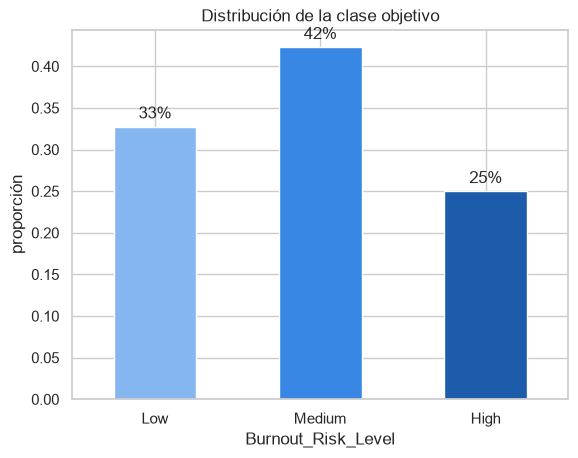

In [2]:
proporciones = df[TARGET_COL].value_counts(normalize=True).reindex(LABELS)
ax = proporciones.plot.bar(color=["#86b6ef", "#3987e5", "#1c5cab"], rot=0)
ax.set(title="Distribución de la clase objetivo", ylabel="proporción")
for i, v in enumerate(proporciones):
    ax.text(i, v + 0.01, f"{v:.0%}", ha="center")
plt.show()

### ✏️ Ejercicio 1 — ¿Por qué F1 macro y no accuracy?
Un modelo "tonto" que **siempre** predice la clase más frecuente, ¿qué accuracy tendría?
Calculalo con `proporciones` y guardalo en `acc_tonto`.

In [3]:
acc_tonto = None  # ← tu código acá

In [4]:
safe_check(
    "Ejercicio 1",
    lambda: abs(acc_tonto - proporciones.max()) < 1e-9,
    "es la proporción de la clase más frecuente: `proporciones.max()`.",
)

⏳ **Ejercicio 1**: todavía no. *Pista:* es la proporción de la clase más frecuente: `proporciones.max()`. (error: `TypeError: unsupported operand type(s) for -: 'NoneType' and 'float'`)

False

<details><summary>Ver solución</summary>

```python
acc_tonto = proporciones.max()   # ≈ 0.42 (Medium)
```
Con 42 % de accuracy "gratis", la accuracy engaña. El F1 macro de ese modelo sería ≈ 0,20 (es el
*Dummy* de la tabla de AMq1), porque castiga no acertar nunca Low ni High.
</details>

## 2. 🎛️ Explorá las features contra el burnout
Elegí una variable y mirá cómo cambia su distribución según el nivel de burnout.

In [5]:
numericas = FEATURES["numeric"]
categoricas = [*FEATURES["ordinal"], *FEATURES["nominal"], *FEATURES["boolean"]]


@interact(variable=widgets.Dropdown(options=numericas + categoricas, value="Weekly_GenAI_Hours"))
def explorar(variable):
    fig, ax = plt.subplots(figsize=(8, 4))
    if variable in numericas:
        sns.boxplot(data=df, x=TARGET_COL, y=variable, order=LABELS, ax=ax, palette="Blues", hue=TARGET_COL,
                    legend=False)
    else:
        tabla = pd.crosstab(df[variable], df[TARGET_COL], normalize="index")[LABELS]
        tabla.plot.barh(stacked=True, ax=ax, color=["#86b6ef", "#3987e5", "#1c5cab"])
        ax.set_xlabel("proporción dentro de cada categoría")
    ax.set_title(f"{variable} según {TARGET_COL}")
    plt.show()

interactive(children=(Dropdown(description='variable', index=1, options=('Pre_Semester_GPA', 'Weekly_GenAI_Hou…

Lo que encontramos en AMq1 (y deberías ver arriba): **más horas de IA y más dependencia percibida
van con más burnout** (hipótesis H1), mientras que la habilidad de prompting casi no cambia nada (H3).

## 3. Fuga de información (*data leakage*)
El dataset trae otras dos variables "de resultado": `Post_Semester_GPA` y `Skill_Retention_Score`.
Se miden **al final del semestre**, igual que el burnout.

In [6]:
quiz(
    "¿Podemos usar Post_Semester_GPA como feature para predecir el burnout?",
    ["Sí, mejora el modelo", "No: se conoce recién al final del semestre", "Solo si la escalamos"],
    answer=1,
    explanation="Cuando el modelo esté en producción (al inicio del semestre) esa variable todavía no existe. "
    "Usarla daría métricas infladas que no se repiten en la realidad.",
)

**¿Podemos usar Post_Semester_GPA como feature para predecir el burnout?**

ToggleButtons(options=('Sí, mejora el modelo', 'No: se conoce recién al final del semestre', 'Solo si la escal…

Output()

In [7]:
print("Variables excluidas por fuga:", [c for c in OUTCOMES if c != TARGET_COL])
print("Features que usa el modelo:")
for tipo, cols in FEATURES.items():
    print(f"  {tipo:>8}: {cols}")

Variables excluidas por fuga: ['Post_Semester_GPA', 'Skill_Retention_Score']
Features que usa el modelo:
   numeric: ['Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Tool_Diversity', 'Traditional_Study_Hours', 'Perceived_AI_Dependency', 'Anxiety_Level_During_Exams']
   boolean: ['Paid_Subscription']
   ordinal: ['Year_of_Study', 'Prompt_Engineering_Skill']
   nominal: ['Major_Category', 'Primary_Use_Case', 'Institutional_Policy']


## 4. Codificación: ordinal vs one-hot

- **Ordinales** (`Year_of_Study`, `Prompt_Engineering_Skill`): tienen orden → `OrdinalEncoder` con el
  orden explícito (Freshman=0 … Graduate=4).
- **Nominales** (`Major_Category`, `Primary_Use_Case`, `Institutional_Policy`): sin orden → `OneHotEncoder`.

### ✏️ Ejercicio 2 — codificá a mano
Completá `codificar_anio` para que devuelva el número de cada año según el orden de
`ORDINAL["Year_of_Study"]` (Freshman → 0, Sophomore → 1, …).

In [8]:
print(ORDINAL["Year_of_Study"])


def codificar_anio(anio: str) -> int:
    ...  # ← tu código acá

['Freshman', 'Sophomore', 'Junior', 'Senior', 'Graduate']


In [9]:
safe_check(
    "Ejercicio 2",
    lambda: [codificar_anio(a) for a in ["Freshman", "Junior", "Graduate"]] == [0, 2, 4],
    "usá `.index()` sobre la lista `ORDINAL['Year_of_Study']`.",
)

⏳ **Ejercicio 2**: todavía no. *Pista:* usá `.index()` sobre la lista `ORDINAL['Year_of_Study']`.

False

<details><summary>Ver solución</summary>

```python
def codificar_anio(anio: str) -> int:
    return ORDINAL["Year_of_Study"].index(anio)
```
</details>

### ✏️ Ejercicio 3 — ¿cuántas columnas genera el one-hot?
Con las categorías de `NOMINAL`, ¿cuántas columnas salen del `OneHotEncoder` **sin** `drop="first"`
(como en XGBoost)? Guardalo en `n_columnas_onehot`.

In [10]:
n_columnas_onehot = None  # ← tu código acá

In [11]:
safe_check(
    "Ejercicio 3",
    lambda: n_columnas_onehot == sum(len(v) for v in NOMINAL.values()),
    "una columna por cada categoría de cada variable nominal: sumá los `len` de `NOMINAL.values()`.",
)

⏳ **Ejercicio 3**: todavía no. *Pista:* una columna por cada categoría de cada variable nominal: sumá los `len` de `NOMINAL.values()`.

False

<details><summary>Ver solución</summary>

```python
n_columnas_onehot = sum(len(v) for v in NOMINAL.values())   # 5 + 5 + 3 = 13
```
</details>

Comprobémoslo con el preprocesador real del TP (el mismo que usa el DAG de entrenamiento):

In [12]:
from burnout.data import make_split, validate
from burnout.model import build_preprocessor

X_train, X_test, y_train, y_test = make_split(validate(df))
prep = build_preprocessor().fit(X_train)
nombres = prep.get_feature_names_out()
print(f"{len(nombres)} columnas después del preprocesamiento:")
print(list(nombres))

22 columnas después del preprocesamiento:
['Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Tool_Diversity', 'Traditional_Study_Hours', 'Perceived_AI_Dependency', 'Anxiety_Level_During_Exams', 'Paid_Subscription', 'Year_of_Study', 'Prompt_Engineering_Skill', 'Major_Category_STEM', 'Major_Category_Business', 'Major_Category_Humanities', 'Major_Category_Medical', 'Major_Category_Arts', 'Primary_Use_Case_Copywriting/Drafting', 'Primary_Use_Case_Summarizing_Reading', 'Primary_Use_Case_Debugging/Troubleshooting', 'Primary_Use_Case_Ideation', 'Primary_Use_Case_Direct_Answer_Generation', 'Institutional_Policy_Allowed_With_Citation', 'Institutional_Policy_Strict_Ban', 'Institutional_Policy_Actively_Encouraged']


## 5. Split estratificado y por qué se ajusta solo con train
- **Estratificado:** train y test mantienen la misma proporción de Low/Medium/High.
- **Ajustar solo con train:** encoders y escaladores se ajustan con train y se *aplican* a test.
  Si se ajustan con todo, información de test se filtra al entrenamiento.

In [13]:
pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index().values,
    "test": y_test.value_counts(normalize=True).sort_index().values,
}, index=LABELS).round(4)

,train,test
Low,0.3274,0.3274
Medium,0.4229,0.4229
High,0.2498,0.2497


### 🎛️ ¿Qué pasa sin estratificar?
Mové el tamaño de muestra: con pocos datos, un split al azar puede desbalancear mucho las clases.

In [14]:
from sklearn.model_selection import train_test_split


@interact(n=widgets.IntSlider(min=30, max=2000, step=10, value=60), semilla=widgets.IntSlider(min=0, max=20))
def comparar_split(n, semilla):
    muestra = df.sample(n, random_state=semilla)
    y = muestra[TARGET_COL]
    _, _, _, y_te_azar = train_test_split(muestra, y, test_size=0.2, random_state=semilla)
    _, _, _, y_te_estr = train_test_split(muestra, y, test_size=0.2, random_state=semilla, stratify=y)
    tabla = pd.DataFrame({
        "población": y.value_counts(normalize=True),
        "test al azar": y_te_azar.value_counts(normalize=True),
        "test estratificado": y_te_estr.value_counts(normalize=True),
    }).reindex(LABELS).fillna(0)
    print((tabla * 100).round(1).astype(str) + " %")

interactive(children=(IntSlider(value=60, description='n', max=2000, min=30, step=10), IntSlider(value=0, desc…

## Resumen
| Decisión | Por qué | Dónde vive ahora |
|---|---|---|
| Objetivo `Burnout_Risk_Level`, F1 macro | 3 clases desbalanceadas | `burnout/config.py` |
| Excluir GPA post y retención | Fuga de información | `config.OUTCOMES` |
| Ordinal + one-hot | Respetar orden / no inventarlo | `burnout/model.py::build_preprocessor` |
| Split 80/20 estratificado, semilla 42 | Reproducible y comparable | `burnout/data.py::make_split` |

Seguí con **R2 — Modelos, métricas y Optuna**.